# Lab 9 Morphological Operations

**faisal abdullah alshehri** | **Student ID 2240001737**

The input is the uploaded image of a white letter M on a dark background.
Place `Screenshot_1.png` in the same folder as the notebook before running it.
The code uses NumPy, Pillow, SciPy, and Matplotlib.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy.ndimage import (
    binary_closing, binary_dilation, binary_erosion, binary_opening,
)

original = Image.open("Screenshot_1.png").convert("RGB")
gray = np.asarray(original.convert("L"))

# Otsu selects the gray level with the largest between-class variance.
levels = np.arange(256)
histogram = np.bincount(gray.ravel(), minlength=256).astype(float)
lower_count = histogram.cumsum()
upper_count = lower_count[-1] - lower_count
lower_sum = (histogram * levels).cumsum()
denominator = lower_count * upper_count
numerator = (lower_sum[-1] * lower_count - lower_sum * lower_count[-1]) ** 2
variance = np.divide(numerator, denominator, out=np.zeros(256), where=denominator > 0)
threshold = int(variance.argmax())
binary = gray > threshold

print(f"Otsu threshold: {threshold}")
print(f"White foreground pixels: {np.count_nonzero(binary):,}")

Otsu threshold: 124
White foreground pixels: 60,809


## Task 1 · Apply the four operations

Each operation starts with the same binary image and uses an 11×11 square
structuring element. This size makes the effects on the specks and holes visible.

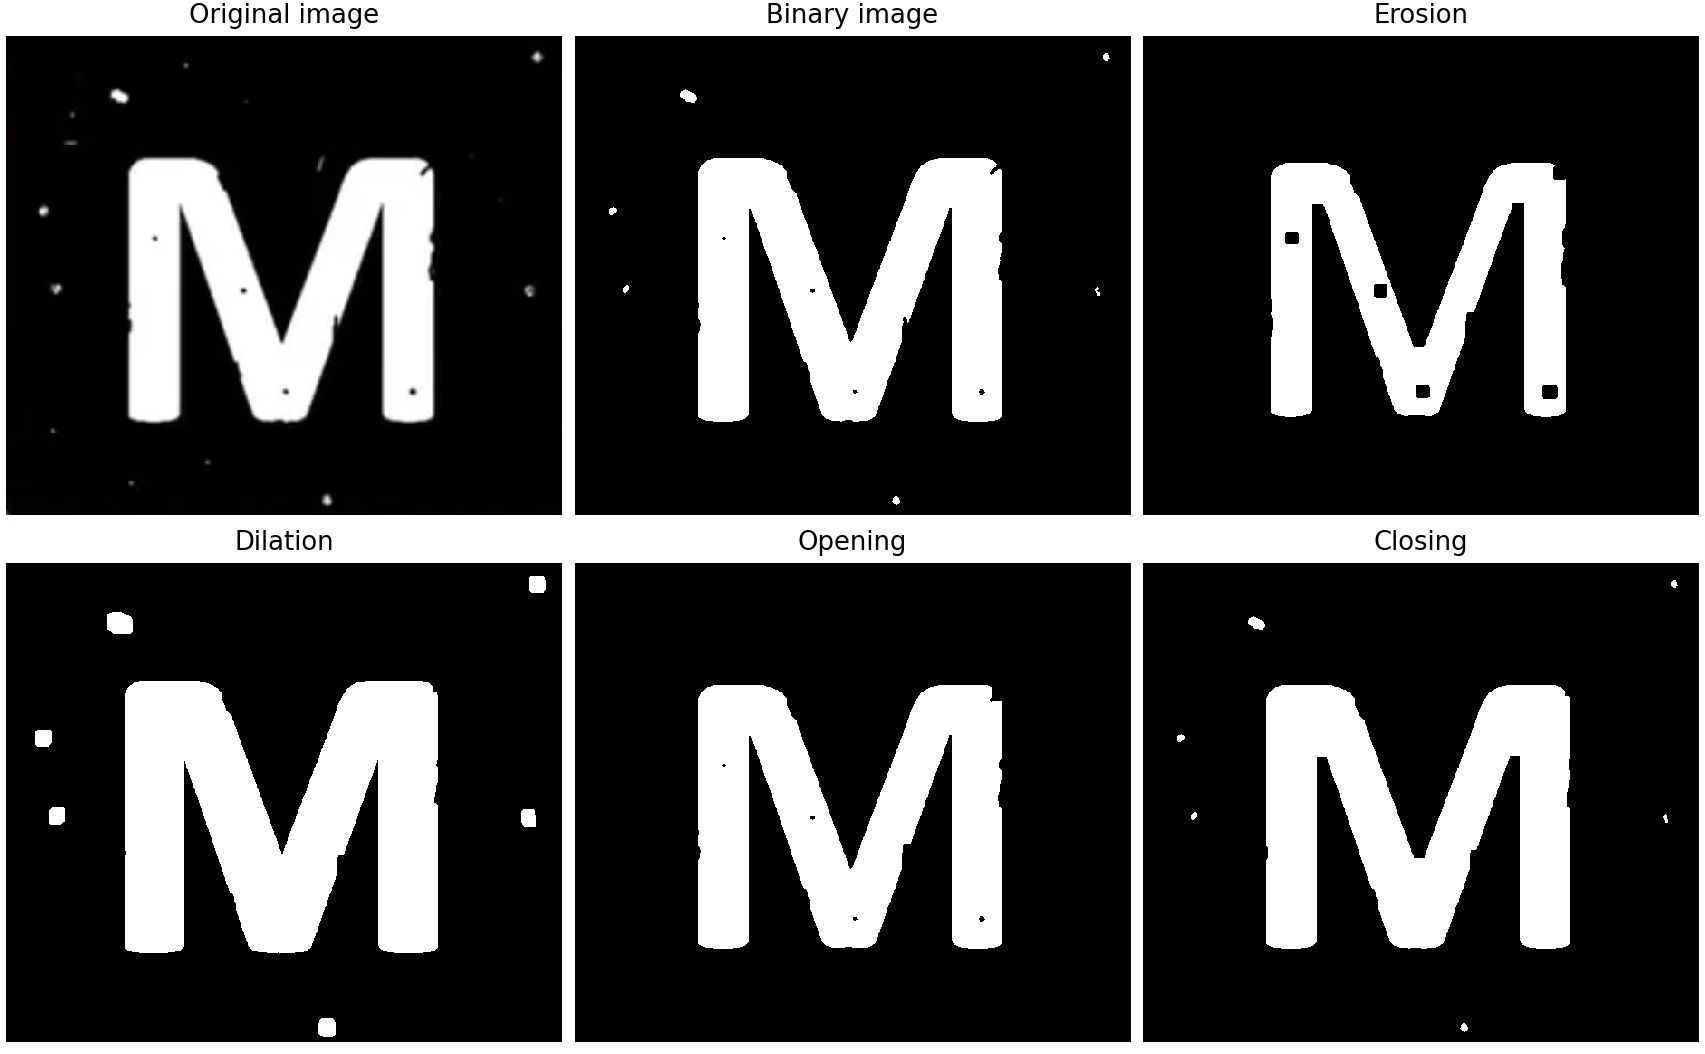

In [2]:
kernel = np.ones((11, 11), dtype=bool)
task1_results = {
    "Erosion": binary_erosion(binary, structure=kernel),
    "Dilation": binary_dilation(binary, structure=kernel),
    "Opening": binary_opening(binary, structure=kernel),
    "Closing": binary_closing(binary, structure=kernel),
}

panels = {"Original image": original, "Binary image": binary, **task1_results}
fig, axes = plt.subplots(2, 3, figsize=(11, 6.8), layout="constrained")
for ax, (name, result) in zip(axes.flat, panels.items()):
    ax.imshow(result, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
plt.show()

### Observations

- **Erosion.** The white strokes got thinner and the dark holes grew.
- **Dilation.** The white strokes got thicker and the dark holes disappeared.
- **Opening.** The six isolated white specks disappeared. The letter and its four holes remained.
- **Closing.** All four holes inside the letter filled in and small notches along the edge became smoother.

## Task 2 · Compare structuring elements

Apply erosion and dilation to the same binary image using square, cross,
and ellipse structuring elements at 3×3, 5×5, and 7×7.

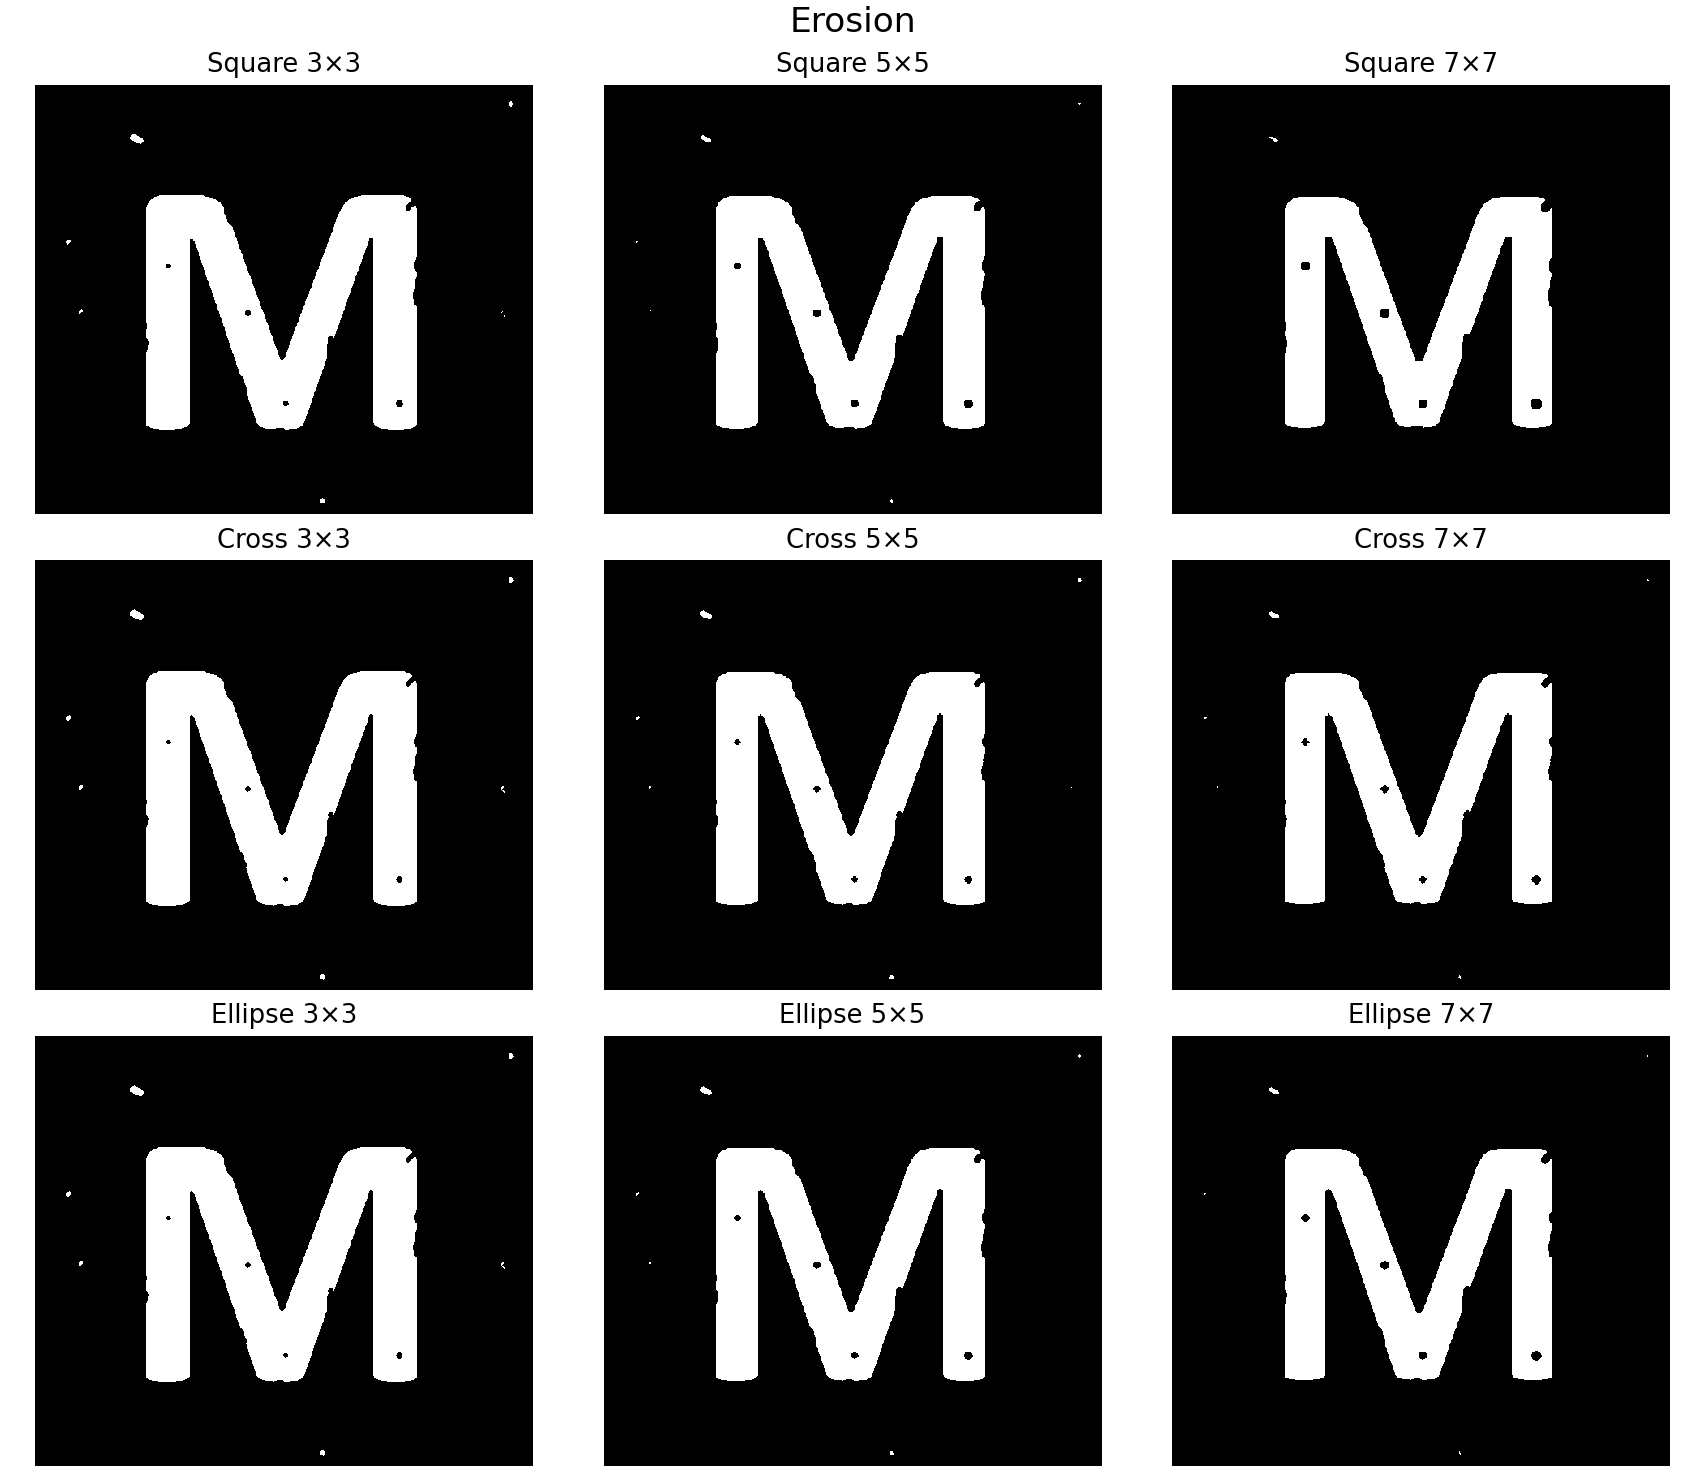

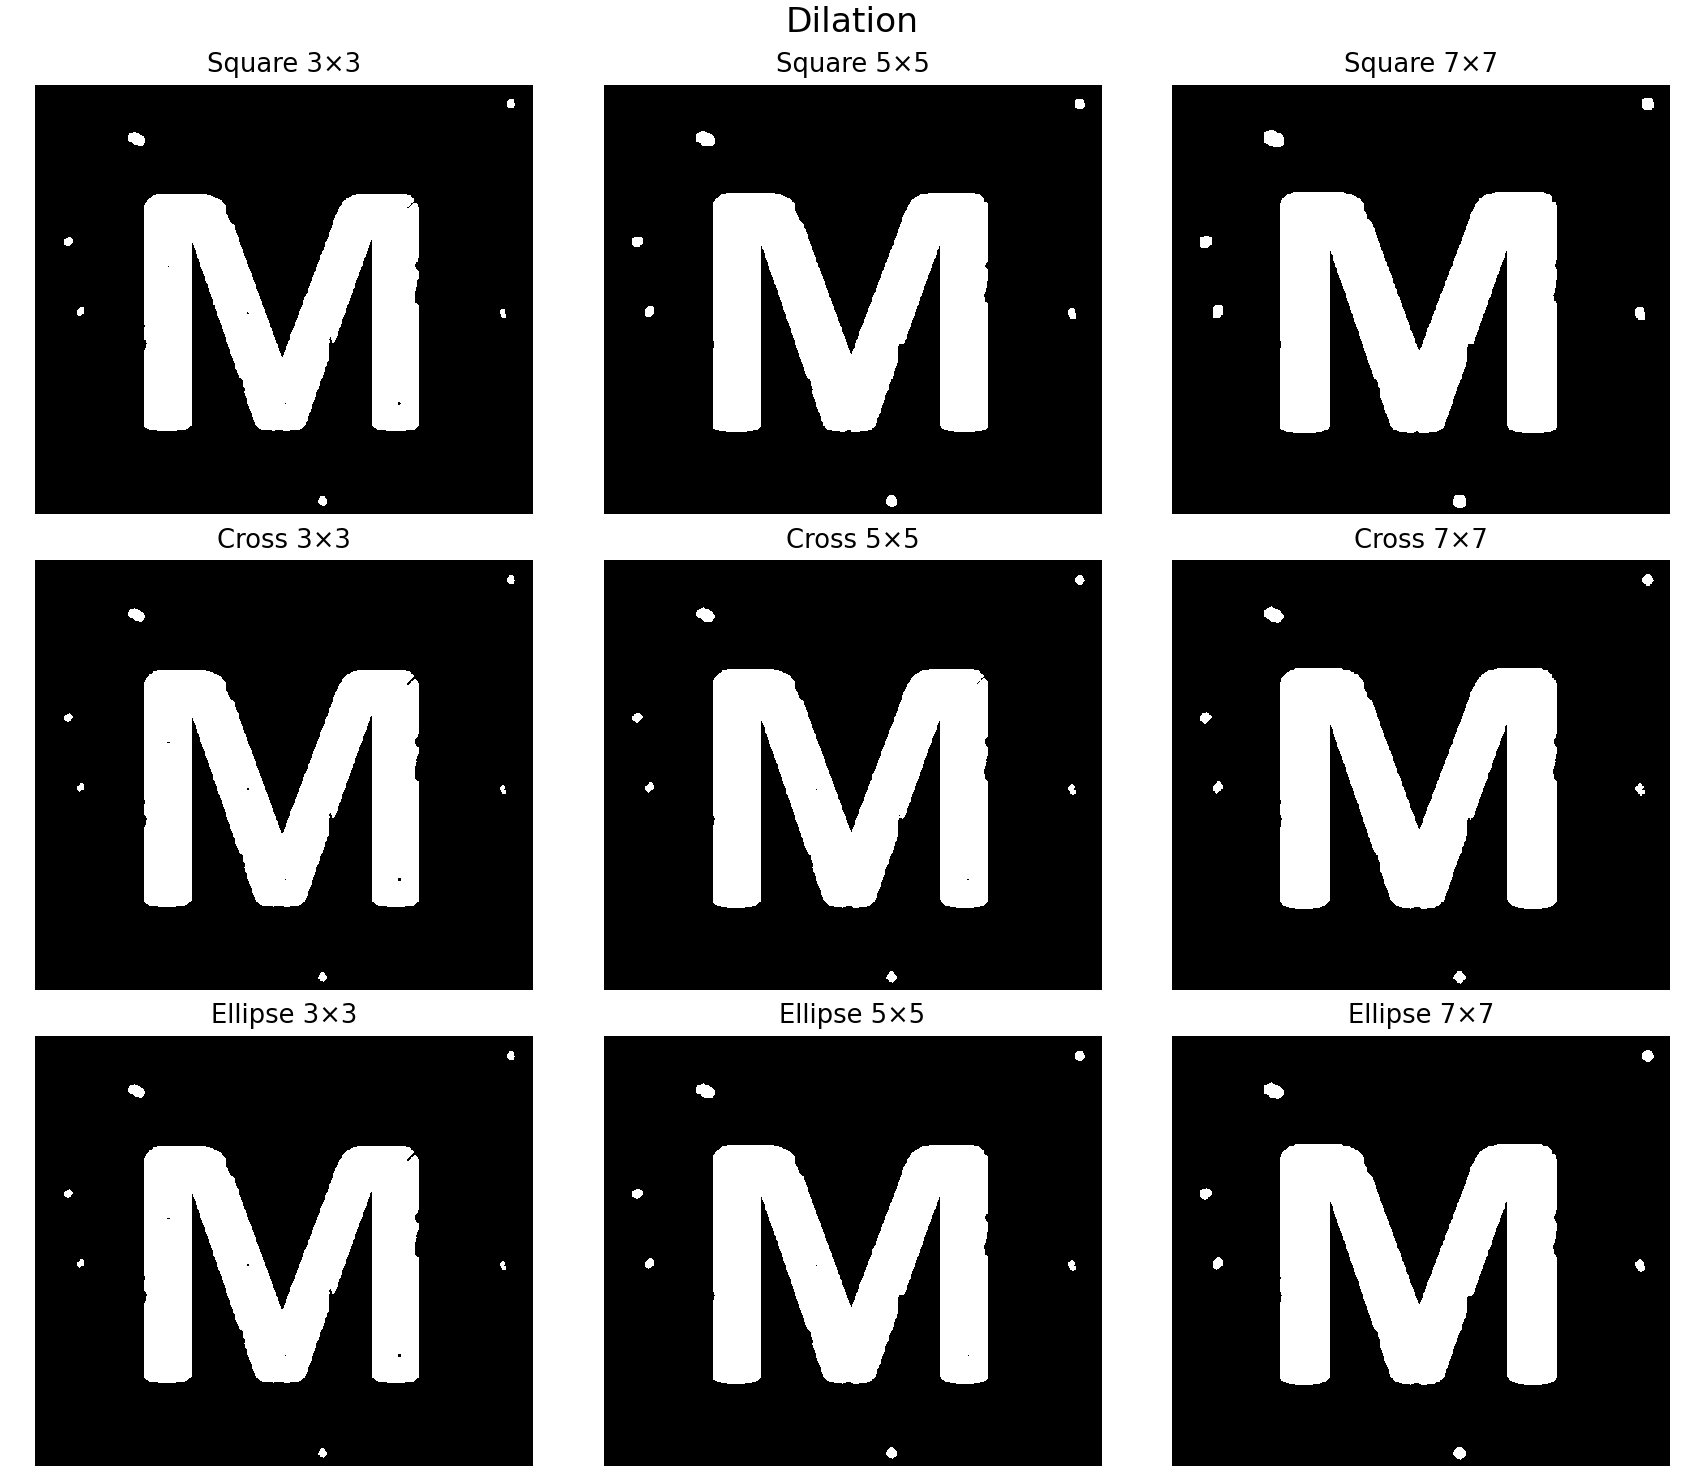

In [3]:
shapes = ("Square", "Cross", "Ellipse")
sizes = (3, 5, 7)
kernels = {}

for size in sizes:
    radius = size // 2
    offsets = np.arange(-radius, radius + 1)
    rows = offsets[:, None]
    columns = offsets[None, :]
    # Rasterize an ellipse by rounding its horizontal radius on each row.
    half_widths = np.rint(np.sqrt(radius**2 - offsets**2))[:, None]

    kernels["Square", size] = np.ones((size, size), dtype=bool)
    kernels["Cross", size] = (rows == 0) | (columns == 0)
    kernels["Ellipse", size] = np.abs(columns) <= half_widths

operations = {"Erosion": binary_erosion, "Dilation": binary_dilation}
task2_results = {}

for name, operation in operations.items():
    results = {}
    fig, axes = plt.subplots(3, 3, figsize=(11, 9.5), layout="constrained")
    fig.suptitle(name, fontsize=16)
    for row, shape in enumerate(shapes):
        for col, size in enumerate(sizes):
            result = operation(binary, structure=kernels[shape, size])
            results[shape, size] = result
            ax = axes[row, col]
            ax.imshow(result, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
            ax.set_title(f"{shape} {size}×{size}")
            ax.axis("off")
    task2_results[name] = results
    plt.show()

In [4]:
print("White foreground pixels after each operation")
print()
print(f"{'Shape':<8} {'Kernel':>7} {'Erosion':>10} {'Dilation':>10}")
for shape in shapes:
    for size in sizes:
        eroded = np.count_nonzero(task2_results["Erosion"][shape, size])
        dilated = np.count_nonzero(task2_results["Dilation"][shape, size])
        print(f"{shape:<8} {f'{size}×{size}':>7} {eroded:>10,} {dilated:>10,}")

White foreground pixels after each operation

Shape     Kernel    Erosion   Dilation
Square       3×3     57,822     63,820
Square       5×5     54,907     66,809
Square       7×7     52,050     69,780
Cross        3×3     58,352     63,278
Cross        5×5     55,937     65,732
Cross        7×7     53,574     68,143
Ellipse      3×3     58,352     63,278
Ellipse      5×5     55,492     66,203
Ellipse      7×7     53,092     68,658


### Comparison

**Erosion.** Larger kernels thinned the white strokes more for each shape. At every size, the square removed the most white pixels and the cross removed the fewest, with the cross and ellipse tied at 3×3.

**Dilation.** Larger kernels thickened the strokes and enlarged the specks. At every size, the square added the most white pixels and the cross added the fewest, with the cross and ellipse tied at 3×3.

**Kernel shape.** The cross and ellipse have the same five active pixels at 3×3, so their results match. At 5×5 and 7×7, the ellipse covers more neighboring pixels and produces white-pixel counts between those of the cross and square.